# EMQA_L7_dm_matrix

**DM tests: combinations with ML beat AW-LEAR significantly**

Energy Markets Quantitative Analysis (EMQA), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L7/EMQA_L7_dm_matrix/EMQA_L7_dm_matrix.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Matrix of one-sided Diebold-Mariano (DM) p-values (H1: the column model is more accurate than the row model; loss = daily mean absolute error; Newey-West variance, 7 lags) for 11 forecasts of the Romanian day-ahead price: naive, AW-LEAR, the Lecture 2 ensemble, XGBoost, DNN, Chronos-Bolt, Chronos-2 and four combinations; test year 2025-11-01 to 2026-10-31, 365 days. Data: test year 2025-11-01 to 2026-10-31, 365 days; one-sided p-values. Source: energy-charts.info (Fraunhofer ISE): OPCOM prices, ENTSO-E load, generation and flows; Yahoo Finance (EUA ETC).

The numbers printed at the end are those on the slide of Lecture 7.

## Setup: chart style and helpers

In [2]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def save_chart(fig, name, bottom=0.17):
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + ".png", dpi=150, bbox_inches="tight", transparent=True)
    plt.show()


def show(label, value, fmt=""):
    """Print a number that appears on the slide."""
    print(f"{label}: {format(value, fmt)}")

LAB = {"naive": "Naive", "aw_arx": "AW-ARX", "aw_lear": "AW-LEAR", "ens4": "Ens. of 4 (L2)", "gbm2": "GBM (L2)",
       "mlp2": "MLP (L2)", "xgb": "XGBoost", "dnn": "DNN", "bolt": "Chronos-Bolt", "chr2": "Chronos-2", "ens_ld": "LEAR+DNN",
       "ens_lx": "LEAR+XGBoost", "ens_ldx": "LEAR+DNN+XGBoost", "ens_t4": "Ens. of 4, tuned ML",
       "ens_t5": "Ens. of 5 (with Chronos-2)", "ens_lc": "LEAR+Chronos-2"}
COL = {"naive": "#9a9a9a", "aw_arx": PAL["HU"], "aw_lear": PAL["RO"], "ens4": PAL["c5"], "gbm2": "#c9a14a", "mlp2": "#a99be0",
       "xgb": PAL["BG"], "dnn": PAL["c7"], "bolt": "#6b6b6b", "chr2": PAL["c8"], "ens_ld": PAL["c6"], "ens_lx": PAL["c6"],
       "ens_ldx": PAL["DE_LU"], "ens_t4": PAL["DE_LU"], "ens_t5": PAL["DE_LU"], "ens_lc": "#7a1f1f"}

## Data: Romanian day-ahead prices, CET delivery day x 24 hours

In [3]:
TZ = "Europe/Brussels"


def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


# Romanian day-ahead price (OPCOM PZU), hourly; after 1 Oct 2025 the hour is the mean of its four quarter-hours
HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", usecols=["timestamp_utc", "RO"], index_col=0)
PM_ALL, DST = day_matrix(HP["RO"].dropna())          # all CET delivery days since 2015 x 24 hours
# sample of the lecture: 2022-01-01 to the cut-off 2026-10-31 (last complete month at the download of 2026-11-04)
START, END = pd.Timestamp("2022-01-01"), pd.Timestamp("2026-10-31")
CAL = pd.date_range(START, END, freq="D")
PM = PM_ALL.reindex(CAL)
assert not PM.isna().any().any(), "panel has gaps"
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
FIRST = 7                                             # first usable target row (needs the price of d-7)
TEST0 = END - pd.Timedelta(days=364)                  # test year = the last 365 days (as in Lecture 2)
VAL0 = TEST0 - pd.Timedelta(days=365)                 # validation year = the 365 days before it
TDAYS = pd.date_range(TEST0, END, freq="D")
VDAYS = pd.date_range(VAL0, TEST0 - pd.Timedelta(days=1), freq="D")
rows_all = np.array([IDX[t] for t in TDAYS])
A = P_[rows_all]                                      # actual prices of the test year (365 days x 24 hours), EUR/MWh
print("panel", CAL[0].date(), "to", CAL[-1].date(), "| test year", TEST0.date(), "to", END.date(), A.shape)

panel 2022-01-01 to 2026-10-31 | test year 2025-11-01 to 2026-10-31 (365, 24)


## Model outputs: saved, or recomputed with `RUN_ALL = True`

The models of this chart take several hours on one core (all benchmarks of Lecture 2, the DNN, XGBoost and two foundation models) to refit, more than a free Colab session allows. With `RUN_ALL = False` the notebook loads their saved outputs (`dm_matrix_results.npz`, produced by `lectures/L7/analysis_L7.py`); with `RUN_ALL = True` it recomputes them from the data with the code below, which is the code of the lecture.

In [4]:
RUN_ALL = False      # True: recompute the model outputs from the data (needs torch, xgboost, scikit-learn, chronos-forecasting)

Code of the models (copied from `lectures/L7/analysis_L7.py` and `lectures/L2/analysis_L2.py`); defining the functions takes no time.

In [5]:
import os
import time

# constants of lectures/L7/analysis_L7.py
SEED = 20261106
PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)            # price lags (days) and lags of load, wind+solar (>= 2 days)
XGB_NAMES = ['P(d-1,h)', 'P(d-2,h)', 'P(d-3,h)', 'P(d-7,h)', 'P(d-1,23)', 'min P(d-1)', 'max P(d-1)', 'mean P(d-1)', 'L(d-2,h)', 'L(d-7,h)', 'RES(d-2,h)', 'RES(d-7,h)', 'mean L(d-2)', 'mean RES(d-2)', 'hydro(d-2)', 'nuclear(d-2)', 'net imports(d-2)', 'EUA(d-2)', 'hour', 'day of week']
# configurations chosen by random search on the validation year (Quantlet EMQA_L7_search)
CFG_DNN = {'n1': 512, 'n2': 0, 'act': 'softplus', 'drop': 0.1, 'lr': 0.0003, 'wd': 1e-05, 'l1': 0.0, 'batch': 64, 'load': True, 'res': True, 'fund': True, 'p3': True}
CFG_XGB = {'n_est': 1500, 'eta': 0.02, 'depth': 8, 'mcw': 5, 'sub': 0.8, 'col': 1.0, 'lam': 0.1, 'obj': 'reg:absoluteerror'}
CTX = 2048                                     # context: the last 2048 hourly prices up to the end of d-1
SEED_L2 = 20261105                                # seed of Lecture 2
ARX_W, LEAR_W = (56, 84, 112, 714, 721, 728), (364, 546, 728)
GBM_NAMES = XGB_NAMES


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def blocks_of(days, freq="M"):
    """(first row, last row) of each calendar month (or quarter) of a day range."""
    out = []
    for _, g in pd.Series(days, index=days).groupby(days.to_period(freq)):
        out.append((IDX[g.index[0]], IDX[g.index[-1]]))
    return out


def dnn_inputs(Pa, La, Ra, Fa, rows, sc, cfg):
    """Input vector of day d (rows): asinh-scaled prices of d-1, d-2, (d-3), d-7 (24 h each), load and wind+solar of d-2, d-3, d-7,
    the 4 daily fundamentals of d-2 and day-of-week dummies. Returns the matrix and the column range of each block."""
    m, s, mL, sL, mR, sR = sc
    cols, names = [], []
    for k in PLAGS:
        if k == 3 and not cfg["p3"]:
            continue
        cols.append(np.arcsinh((shift_rows(Pa, k)[rows] - m) / s))
        names += [f"price d-{k}"] * 24
    if cfg["load"]:
        for k in XLAGS:
            cols.append(np.arcsinh((shift_rows(La, k)[rows] - mL) / sL))
            names += ["load"] * 24
    if cfg["res"]:
        for k in XLAGS:
            cols.append(np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR))
            names += ["wind+solar"] * 24
    if cfg["fund"]:
        cols.append(Fa[rows])
        names += ["hydro", "nuclear", "net imports", "carbon"]
    cols.append(np.eye(7)[DOW[rows]])
    names += ["day of week"] * 7
    return np.column_stack(cols), np.array(names)


def _net(n_in, cfg):
    import torch.nn as nn
    act = nn.ReLU if cfg["act"] == "relu" else nn.Softplus
    layers, prev = [], n_in
    for h in [cfg["n1"]] + ([cfg["n2"]] if cfg["n2"] else []):
        layers += [nn.Linear(prev, h), act(), nn.Dropout(cfg["drop"])]
        prev = h
    layers.append(nn.Linear(prev, 24))
    return nn.Sequential(*layers)


def _train(X, Y, cfg, seed, epochs, Xv=None, yv_eur=None, m=0.0, s=1.0, patience=25):
    """Mini-batch Adam on the mean absolute error of the asinh price; L1 penalty on the input layer (Lago et al. 2021).
    With a validation block: returns the epoch with the lowest validation MAE (EUR/MWh) and the learning curves."""
    import torch
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    Xt, Yt = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
    net = _net(X.shape[1], cfg)
    opt = torch.optim.Adam(net.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    first = net[0].weight
    curve_tr, curve_v, best, best_ep, since = [], [], np.inf, 1, 0
    for ep_ in range(1, epochs + 1):
        net.train()
        perm = rng.permutation(len(X))
        for b0 in range(0, len(X), cfg["batch"]):
            ix = perm[b0:b0 + cfg["batch"]]
            opt.zero_grad()
            loss = (net(Xt[ix]) - Yt[ix]).abs().mean() + cfg["l1"] * first.abs().sum() / first.numel()
            loss.backward()
            opt.step()
        if Xv is not None:
            net.eval()
            with torch.no_grad():
                ptr = m + s * np.sinh(net(Xt).numpy())
                pv = m + s * np.sinh(net(torch.tensor(Xv, dtype=torch.float32)).numpy())
            curve_tr.append(float(np.mean(np.abs(ptr - (m + s * np.sinh(Y))))))
            v = float(np.mean(np.abs(pv - yv_eur)))
            curve_v.append(v)
            if v < best - 1e-9:
                best, best_ep, since = v, ep_, 0
            else:
                since += 1
                if since >= patience:
                    break
    net.eval()
    return net, best_ep, curve_tr, curve_v


def dnn_block(Pa, La, Ra, Fa, i0, i1, cfg, seeds=(1,), max_ep=300, keep=False, lo=FIRST):
    """Fit on target rows lo..i0-1 (all before the block), forecast rows i0..i1.
    Step 1: transforms from rows up to the start of the early-stopping block; train on the first 85% of the training days,
    early-stop on the last 15% (chronological). Step 2: transforms from all training rows; refit for the chosen number of
    epochs on all training days; forecast. Seeds averaged."""
    import torch
    torch.set_num_threads(1)
    t0 = time.perf_counter()
    tr = np.arange(lo, i0)
    cut = int(len(tr) * 0.85)
    v0 = tr[cut]
    sc0 = (*mad_scale(Pa[lo:v0]), *mad_scale(La[lo:v0 - 1]), *mad_scale(Ra[lo:v0 - 1]))
    X0, _ = dnn_inputs(Pa, La, Ra, Fa, tr, sc0, cfg)
    Y0 = np.arcsinh((Pa[tr] - sc0[0]) / sc0[1])
    mu0, sg0 = X0[:cut].mean(0), X0[:cut].std(0)
    sg0[sg0 == 0] = 1
    sc = (*mad_scale(Pa[tr]), *mad_scale(La[lo:i0 - 1]), *mad_scale(Ra[lo:i0 - 1]))
    X, names = dnn_inputs(Pa, La, Ra, Fa, tr, sc, cfg)
    Y = np.arcsinh((Pa[tr] - sc[0]) / sc[1])
    mu, sg = X.mean(0), X.std(0)
    sg[sg == 0] = 1
    te = np.arange(i0, i1 + 1)
    Xte, _ = dnn_inputs(Pa, La, Ra, Fa, te, sc, cfg)
    preds, epochs, curves, models = [], [], [], []
    for sd in seeds:
        _, best_ep, ctr, cv = _train((X0[:cut] - mu0) / sg0, Y0[:cut], cfg, sd, max_ep, (X0[cut:] - mu0) / sg0,
                                     Pa[tr[cut:]], sc0[0], sc0[1])
        net, _, _, _ = _train((X - mu) / sg, Y, cfg, sd, best_ep)
        with torch.no_grad():
            preds.append(sc[0] + sc[1] * np.sinh(net(torch.tensor((Xte - mu) / sg, dtype=torch.float32)).numpy()))
        epochs.append(best_ep)
        curves.append((ctr, cv))
        if keep:
            models.append({k: v.clone() for k, v in net.state_dict().items()})
    out = {"pred": np.mean(preds, 0), "epochs": epochs, "sec": time.perf_counter() - t0, "n_seeds": len(seeds)}
    if keep:
        out.update({"models": models, "mu": mu, "sg": sg, "sc": sc, "names": names, "curves": curves})
    return out


def dnn_predict_from(state, cfg, X, mu, sg, sc):
    import torch
    torch.set_num_threads(1)
    preds = []
    for st in state:
        net = _net(X.shape[1], cfg)
        net.load_state_dict(st)
        net.eval()
        with torch.no_grad():
            preds.append(sc[0] + sc[1] * np.sinh(net(torch.tensor((X - mu) / sg, dtype=torch.float32)).numpy()))
    return np.mean(preds, 0)


def gbm_rows(Pa, La, Ra, Fa, rows, leak=False):
    """Long-format features for (day, hour) pairs (the 20 features of the L2 GBM). leak=True adds the realised load and
    wind+solar of the delivery hour itself (NOT known at gate closure: used only to measure the look-ahead pitfall)."""
    P1, P2, P3, P7 = (shift_rows(Pa, k) for k in PLAGS)
    L2_, L7_, R2_, R7_ = shift_rows(La, 2), shift_rows(La, 7), shift_rows(Ra, 2), shift_rows(Ra, 7)
    feats = []
    for h in range(24):
        f = [P1[rows, h], P2[rows, h], P3[rows, h], P7[rows, h], P1[rows, 23], P1[rows].min(1), P1[rows].max(1),
             P1[rows].mean(1), L2_[rows, h], L7_[rows, h], R2_[rows, h], R7_[rows, h], L2_[rows].mean(1),
             R2_[rows].mean(1), Fa[rows], np.full(len(rows), h), DOW[rows]]
        if leak:
            f += [La[rows, h], Ra[rows, h]]
        feats.append(np.column_stack(f))
    return np.stack(feats, 1)


def _xgb(cfg, seed):
    import xgboost as xgb
    return xgb.XGBRegressor(n_estimators=cfg["n_est"], learning_rate=cfg["eta"], max_depth=cfg["depth"],
                            min_child_weight=cfg["mcw"], subsample=cfg["sub"], colsample_bytree=cfg["col"],
                            reg_lambda=cfg["lam"], objective=cfg["obj"], tree_method="hist", n_jobs=1, random_state=seed,
                            max_leaves=cfg.get("leaves", 0), grow_policy=cfg.get("grow", "depthwise"))


def xgb_block(Pa, La, Ra, Fa, i0, i1, cfg, seed=SEED, lo=FIRST, leak=False, shap=False):
    """Fit on target rows lo..i0-1, forecast rows i0..i1. Target = asinh((P-m)/s), m and s from the training prices."""
    t0 = time.perf_counter()
    tr = np.arange(lo, i0)
    m, s = mad_scale(Pa[tr])
    p = len(XGB_NAMES) + (2 if leak else 0)
    Xtr = gbm_rows(Pa, La, Ra, Fa, tr, leak).reshape(-1, p)
    ytr = np.arcsinh((Pa[tr] - m) / s).ravel()
    mdl = _xgb(cfg, seed).fit(Xtr, ytr)
    te = np.arange(i0, i1 + 1)
    Xte = gbm_rows(Pa, La, Ra, Fa, te, leak).reshape(-1, p)
    y = mdl.predict(Xte).reshape(len(te), 24)
    out = {"pred": m + s * np.sinh(y), "sec": time.perf_counter() - t0}
    if shap:
        import xgboost as xgb
        con = mdl.get_booster().predict(xgb.DMatrix(Xte), pred_contribs=True)      # exact SHAP values (Lundberg et al. 2020)
        out.update({"shap": con.reshape(len(te), 24, p + 1), "m": m, "s": s, "X": Xte.reshape(len(te), 24, p)})
    return out


def chronos_forecasts(Pa, rows, model):
    """Zero-shot: context = the last CTX hourly prices up to the end of d-1 (all known at gate closure), horizon 24 h."""
    import torch
    from chronos import BaseChronosPipeline
    torch.set_num_threads(1)                                    # one core, as for the other models (timing)
    pipe = BaseChronosPipeline.from_pretrained(model, device_map="cpu")
    t0 = time.perf_counter()
    ctx = np.stack([Pa[:i].ravel()[-CTX:] for i in rows]).astype("float32")
    x = torch.tensor(ctx)
    if "chronos-2" in model:
        x = x[:, None, :]
    q, _ = pipe.predict_quantiles(x, prediction_length=24, quantile_levels=[0.1, 0.5, 0.9])
    q = (torch.stack([x_.reshape(24, 3) for x_ in q]) if isinstance(q, list) else q).numpy().reshape(len(rows), 24, 3)
    return {"median": q[:, :, 1], "q": q, "sec": time.perf_counter() - t0}


# ---- benchmarks of Lecture 2 (lectures/L2/analysis_L2.py)
def lear_design(Pa, La, Ra, lo, i):
    """LEAR regressors (Assignment 1: 247 columns) for rows lo..i, with transforms fitted on rows available at gate closure."""
    m, s = mad_scale(Pa[lo - 7:i])
    mL, sL = mad_scale(La[lo - 7:i - 1])
    mR, sR = mad_scale(Ra[lo - 7:i - 1])
    rows = slice(lo, i + 1)
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks.append(np.eye(7)[DOW[rows]])
    X = np.column_stack(blocks)
    Y = np.arcsinh((Pa[rows] - m) / s)
    return X, Y, m, s


def lear_day(Pa, La, Ra, i, T):
    from sklearn.linear_model import LassoLarsIC
    lo = i - T
    X, Y, m, s = lear_design(Pa, La, Ra, lo, i)
    mu, sd = X[:-1].mean(0), X[:-1].std(0)
    sd[sd == 0] = 1.0
    Xs = (X - mu) / sd
    out, nz = np.zeros(24), np.zeros((24, X.shape[1]), bool)
    for h in range(24):
        mdl = LassoLarsIC(criterion="aic", max_iter=2000).fit(Xs[:-1], Y[:-1, h])
        out[h] = mdl.predict(Xs[-1:])[0]
        nz[h] = mdl.coef_ != 0
    return m + s * np.sinh(out), nz


def arx_day(Pa, La, Ra, Fa, i, T, kind="asinh"):
    """Expert ARX (Assignment 1, Ziel & Weron 2018 style), one regression per hour; target day = row i.
    Calibration targets rows i-T..i-1; VST median/MAD from price rows i-T-7..i-1; L,R z-scores from rows i-T-7..i-2."""
    P1, P2, P7 = shift_rows(Pa, 1), shift_rows(Pa, 2), shift_rows(Pa, 7)
    lo = i - T
    if kind == "raw":
        m, s = 0.0, 1.0
        f = lambda x: x  # noqa: E731
        finv = f
    else:
        m, s = mad_scale(Pa[lo - 7:i])
        f = lambda x: np.arcsinh((x - m) / s)  # noqa: E731
        finv = lambda y: m + s * np.sinh(y)  # noqa: E731
    rows = slice(lo, i + 1)
    Y, Y1, Y2, Y7 = f(Pa[rows]), f(P1[rows]), f(P2[rows]), f(P7[rows])
    mu_l, sd_l = np.mean(La[lo - 7:i - 1]), np.std(La[lo - 7:i - 1])
    mu_r, sd_r = np.mean(Ra[lo - 7:i - 1]), np.std(Ra[lo - 7:i - 1])
    Lz = (shift_rows(La, 2)[rows] - mu_l) / sd_l
    Rz = (shift_rows(Ra, 2)[rows] - mu_r) / sd_r
    dw = DOW[rows]
    dmy = np.column_stack([dw == 0, dw == 5, dw == 6]).astype(float)
    extra = None
    if kind == "fund":
        Fr = Fa[rows]
        extra = (Fr - np.nanmean(Fr[:-1], axis=0)) / np.nanstd(Fr[:-1], axis=0)
    n = T + 1
    out, coefs = np.zeros(24), np.zeros((24, 12))
    if kind == "single":                                          # one pooled regression, common slopes, hour intercepts
        Xs, ys = [], []
        for h in range(24):
            hd = np.zeros((n, 24))
            hd[:, h] = 1
            Xs.append(np.column_stack([hd, Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1), Lz[:, h], Rz[:, h], dmy]))
            ys.append(Y[:, h])
        Xs, ys = np.stack(Xs, 1), np.stack(ys, 1)                 # n x 24 x p
        Xc, yc = Xs[:-1].reshape(-1, Xs.shape[2]), ys[:-1].ravel()
        b = np.linalg.lstsq(Xc, yc, rcond=None)[0]
        return finv(Xs[-1] @ b), None
    for h in range(24):
        cols = [np.ones(n), Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1)]
        if kind != "noexog":
            cols += [Lz[:, h], Rz[:, h]]
        cols += [dmy[:, 0], dmy[:, 1], dmy[:, 2]]
        X = np.column_stack(cols)
        if h == 23:
            X = np.delete(X, 4, axis=1)                           # Y_{d-1,23} appears twice for h = 23
        if extra is not None:
            X = np.column_stack([X, extra])
        b = np.linalg.lstsq(X[:-1], Y[:-1, h], rcond=None)[0]
        out[h] = X[-1] @ b
        if kind == "asinh" and h != 23 and X.shape[1] == 12:
            coefs[h] = b
    return finv(out), coefs


def gbm_month(Pa, La, Ra, Fa, i0, i1, seed=SEED_L2):
    """Fit on targets rows 7..i0-1 (all before the month), forecast rows i0..i1 (the month)."""
    from sklearn.ensemble import HistGradientBoostingRegressor
    tr = np.arange(7, i0)
    m, s = mad_scale(Pa[tr])
    Xtr = gbm_rows(Pa, La, Ra, Fa, tr).reshape(-1, len(GBM_NAMES))
    ytr = np.arcsinh((Pa[tr] - m) / s).ravel()
    mdl = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
                                        l2_regularization=1.0, early_stopping=False, random_state=seed,
                                        categorical_features=[18, 19]).fit(Xtr, ytr)
    te = np.arange(i0, i1 + 1)
    pr = mdl.predict(gbm_rows(Pa, La, Ra, Fa, te).reshape(-1, len(GBM_NAMES))).reshape(len(te), 24)
    return m + s * np.sinh(pr), mdl


def mlp_design(Pa, La, Ra, Fa, rows, m, s, mL, sL, mR, sR):
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks += [Fa[rows], np.eye(7)[DOW[rows]]]
    return np.column_stack(blocks)


def mlp_month(Pa, La, Ra, Fa, i0, i1, seeds=(1, 2, 3, 4), max_ep=150):
    """Multi-output network (24 outputs, Lago et al. 2021 style DNN, small). Epochs chosen on a CHRONOLOGICAL validation
    block (last 15% of the training days); then refitted on all training days with that number of epochs."""
    from sklearn.neural_network import MLPRegressor
    tr = np.arange(7, i0)
    cut = int(len(tr) * 0.85)
    v0 = tr[cut]                                                # first validation day: transforms frozen at its gate closure
    m0, s0 = mad_scale(Pa[7:v0])
    mL0, sL0 = mad_scale(La[7:v0 - 1])
    mR0, sR0 = mad_scale(Ra[7:v0 - 1])
    X0 = mlp_design(Pa, La, Ra, Fa, tr, m0, s0, mL0, sL0, mR0, sR0)
    Y0 = np.arcsinh((Pa[tr] - m0) / s0)
    m, s = mad_scale(Pa[tr])                                    # final refit: everything available before the month
    mL, sL = mad_scale(La[7:i0 - 1])
    mR, sR = mad_scale(Ra[7:i0 - 1])
    X = mlp_design(Pa, La, Ra, Fa, tr, m, s, mL, sL, mR, sR)
    Y = np.arcsinh((Pa[tr] - m) / s)
    te = np.arange(i0, i1 + 1)
    Xte = mlp_design(Pa, La, Ra, Fa, te, m, s, mL, sL, mR, sR)
    preds, epochs = [], []
    for sd in seeds:
        mu, sg = X0[:cut].mean(0), X0[:cut].std(0)
        sg[sg == 0] = 1
        net = MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, learning_rate_init=1e-3, batch_size=64, random_state=sd)
        best, best_ep = np.inf, 1
        for ep_ in range(1, max_ep + 1):
            net.partial_fit((X0[:cut] - mu) / sg, Y0[:cut])
            v = np.mean(np.abs(m0 + s0 * np.sinh(net.predict((X0[cut:] - mu) / sg)) - Pa[tr[cut:]]))
            if v < best:
                best, best_ep = v, ep_
        mu, sg = X.mean(0), X.std(0)
        sg[sg == 0] = 1
        net = MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, learning_rate_init=1e-3, batch_size=64, random_state=sd)
        for _ in range(best_ep):
            net.partial_fit((X - mu) / sg, Y)
        preds.append(m + s * np.sinh(net.predict((Xte - mu) / sg)))
        epochs.append(best_ep)
    return np.mean(preds, 0), epochs


QL = "EMQA_L7_dm_matrix"


def load_results(fname):
    """Saved outputs of the full computation, stored in this Quantlet folder (local copy, else the public repository)."""
    if os.path.isfile(fname):
        return dict(np.load(fname, allow_pickle=False))
    raw = urllib.request.urlopen(REPO + "Quantlets/L7/" + QL + "/" + fname).read()
    return dict(np.load(io.BytesIO(raw), allow_pickle=False))

In [6]:
if RUN_ALL:
    # ---- full information set at gate closure (12:00 CET on d-1), as in lectures/L7/analysis_L7.py
    from joblib import Parallel, delayed
    GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0)
    LM, _ = day_matrix(GH["load"].dropna())
    RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
    L_, R_ = LM.reindex(CAL).values.astype(float), RM.reindex(CAL).values.astype(float)
    G = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    CB = pd.read_csv(DATA + "crossborder_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    EUA = pd.read_csv(DATA + "eua_daily.csv", parse_dates=["date"]).set_index("date")["eua_etc_co2l_eur_per_unit"]
    CAL_EX = pd.date_range(START - pd.Timedelta(days=30), END, freq="D")
    FUND_RAW = pd.DataFrame({"hydro": (G["hydro_run_of_river"] + G["hydro_water_reservoir"]).reindex(CAL_EX),
                             "nuclear": G["nuclear"].reindex(CAL_EX), "netimp": CB["sum"].reindex(CAL_EX), "eua": EUA.reindex(CAL_EX)})
    F_ = FUND_RAW.ffill().shift(2).reindex(CAL).values.astype(float)      # past only, lagged 2 days
    MB = blocks_of(TDAYS, "M")                                           # 12 monthly refits in the test year
    _vm = blocks_of(VDAYS, "M")
    VB = [(_vm[k][0], _vm[k + 2][1]) for k in range(0, 12, 3)]           # validation year: 4 quarterly refits
    FC = {}
    FC["naive"] = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in rows_all])   # Lecture 2 naive rule
    def _aw_lear(i):
        return np.mean([lear_day(P_, L_, R_, i, T)[0] for T in LEAR_W], 0)
    FC["aw_lear"] = np.array(Parallel(n_jobs=-1)(delayed(_aw_lear)(i) for i in rows_all))      # AW-LEAR (Lecture 2), daily recalibration
    def _aw_arx(i):
        return np.mean([arx_day(P_, L_, R_, F_, i, T)[0] for T in ARX_W], 0)
    FC["aw_arx"] = np.array(Parallel(n_jobs=-1)(delayed(_aw_arx)(i) for i in rows_all))
    FC["gbm2"] = np.vstack([g[0] for g in Parallel(n_jobs=-1)(delayed(gbm_month)(P_, L_, R_, F_, a, b) for a, b in MB)])
    FC["mlp2"] = np.vstack([g[0] for g in Parallel(n_jobs=-1)(delayed(mlp_month)(P_, L_, R_, F_, a, b) for a, b in MB)])
    res_dnn = Parallel(n_jobs=-1)(delayed(dnn_block)(P_, L_, R_, F_, a, b, CFG_DNN, (1, 2, 3, 4), keep=True) for a, b in MB)
    FC["dnn"] = np.vstack([r["pred"] for r in res_dnn])                  # DNN, 4 seeds averaged, monthly refits
    res_xgb = Parallel(n_jobs=-1)(delayed(xgb_block)(P_, L_, R_, F_, a, b, CFG_XGB, shap=True) for a, b in MB)
    FC["xgb"] = np.vstack([r["pred"] for r in res_xgb])                  # XGBoost, monthly refits
    # needs: pip install chronos-forecasting
    chr2 = chronos_forecasts(P_, rows_all, "amazon/chronos-2")
    FC["chr2"], FC["chr2_q10"], FC["chr2_q90"] = chr2["median"], chr2["q"][:, :, 0], chr2["q"][:, :, 2]
    bolt = chronos_forecasts(P_, rows_all, "amazon/chronos-bolt-small")
    FC["bolt"] = bolt["median"]
else:
    FC = load_results("dm_matrix_results.npz")
    assert list(FC.get("days", TDAYS.strftime("%Y-%m-%d"))) == list(TDAYS.strftime("%Y-%m-%d"))
print(sorted(k for k in FC if k != "days"))

['aw_arx', 'aw_lear', 'bolt', 'chr2', 'dnn', 'gbm2', 'mlp2', 'naive', 'xgb']


## Combinations and Diebold-Mariano tests

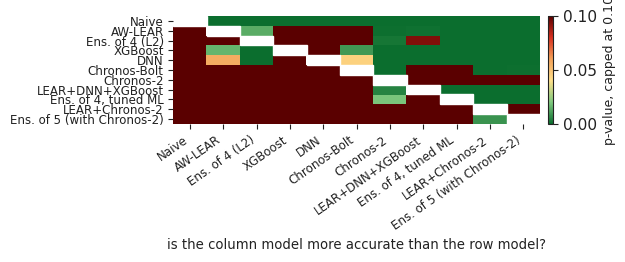

In [7]:
def mae(F):
    return np.mean(np.abs(A - F))


def nw_var(x, lags=7):
    x = x - x.mean()
    n = len(x)
    v = x @ x / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (x[k:] @ x[:-k]) / n
    return v


def dm(ea, eb, lags=7):
    """One-sided DM test (as in L2): H1 = model b more accurate than model a; loss = daily mean |error| over 24 hours."""
    dlt = np.mean(np.abs(ea), 1) - np.mean(np.abs(eb), 1)
    stat = dlt.mean() / np.sqrt(nw_var(dlt, lags) / len(dlt))
    return stat, 1 - stats.norm.cdf(stat)


M = dict(FC)
M["ens4"] = np.mean([M["aw_arx"], M["aw_lear"], M["gbm2"], M["mlp2"]], 0)       # ensemble of 4 of Lecture 2
M["ens_ldx"] = (M["aw_lear"] + M["dnn"] + M["xgb"]) / 3
M["ens_t4"] = np.mean([M["aw_arx"], M["aw_lear"], M["dnn"], M["xgb"]], 0)
M["ens_lc"] = 0.5 * (M["aw_lear"] + M["chr2"])
M["ens_t5"] = np.mean([M["aw_arx"], M["aw_lear"], M["dnn"], M["xgb"], M["chr2"]], 0)
E = {k: A - v for k, v in M.items() if k != "days"}
DM_MODELS = ["naive", "aw_lear", "ens4", "xgb", "dnn", "bolt", "chr2", "ens_ldx", "ens_t4", "ens_lc", "ens_t5"]
DMP = np.full((len(DM_MODELS), len(DM_MODELS)), np.nan)
for a_, ka in enumerate(DM_MODELS):
    for b_, kb in enumerate(DM_MODELS):
        if a_ != b_:
            DMP[a_, b_] = dm(E[ka], E[kb])[1]

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("dm", ["#0b6e2e", "#7fc97f", "#ffe08a", "#f4a259", "#d7301f", "#5a0000"])
fig, ax = plt.subplots(figsize=(6.4, 2.75))
Z = np.where(np.isnan(DMP), np.nan, np.minimum(DMP, 0.10))
im = ax.imshow(np.ma.masked_invalid(Z), cmap=cmap, vmin=0, vmax=0.10, aspect="auto")
ax.set_xticks(range(len(DM_MODELS)))
ax.set_xticklabels([LAB[k] for k in DM_MODELS], rotation=35, ha="right", fontsize=8.5)
ax.set_yticks(range(len(DM_MODELS)))
ax.set_yticklabels([LAB[k] for k in DM_MODELS], fontsize=8.5)
ax.set_xlabel("is the column model more accurate than the row model?", fontsize=9.5)
for a_ in range(len(DM_MODELS)):
    ax.add_patch(plt.Rectangle((a_ - 0.5, a_ - 0.5), 1, 1, color="#ffffff"))
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_label("p-value, capped at 0.10", fontsize=9)
ax.spines[:].set_visible(False)
save_chart(fig, "dm_matrix", bottom=0.0)

## Numbers on the slide

In [8]:
show('DM p-value, AW-LEAR vs LEAR+DNN+XGBoost', dm(E['aw_lear'], E['ens_ldx'])[1], '.4f')
show('MAE AW-ARX + AW-LEAR + DNN + XGBoost', mae(M['ens_t4']), '.2f')
show('DM p-value, ensemble of 4 (L2) vs tuned ensemble of 4', dm(E['ens4'], E['ens_t4'])[1], '.4f')
show('DM p-value, Chronos-2 vs LEAR+Chronos-2', dm(E['chr2'], E['ens_lc'])[1], '.4f')
show('Models significantly better than AW-LEAR (5%)', int(sum(DMP[DM_MODELS.index('aw_lear'), j] < 0.05 for j in range(len(DM_MODELS)))), 'd')

DM p-value, AW-LEAR vs LEAR+DNN+XGBoost: 0.0010
MAE AW-ARX + AW-LEAR + DNN + XGBoost: 21.69
DM p-value, ensemble of 4 (L2) vs tuned ensemble of 4: 0.0000
DM p-value, Chronos-2 vs LEAR+Chronos-2: 0.4907
Models significantly better than AW-LEAR (5%): 6
